<h1 style="color: #9f43c3ff; border-bottom: 3px solid #9f43c3ff; padding-bottom: 8px;">
AI & ML Course with BinX — Week 8 Day 3: Computer Vision Preprocessing & Augmentation
</h1>

<blockquote style="border-left: 3px solid #2e1a9aff; padding-left: 12px; margin-left: 0;">

<b>Day 3 Learning Objectives:</b>
- <b>Step 1 — OpenCV Preprocessing Pipeline:</b> Build a standardized preprocessing function reading images from disk, resizing to fixed dimensions ($224 \times 224$), converting OpenCV default BGR to RGB, and normalizing intensities to $[0.0, 1.0]$.
- <b>Step 2 — Clinical Augmentation Pipeline:</b> Construct an augmentation pipeline using Keras layers to induce rotational, spatial, and contrast invariance.
- <b>Step 3 — Single-Image Augmentation Visualization:</b> Apply the pipeline repeatedly to a single preprocessed image to visualize multiple stochastic variations side-by-side with the original.

</blockquote>


## <span style="color: #39b64eff">1. Step 1: OpenCV Preprocessing Pipeline (Read, Resize, RGB, Normalize)</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

Raw computer vision inputs vary across physical acquisition hardware in resolution, orientation, color space, and intensity distribution. A standardized preprocessing pipeline performs four essential operations:

1. <b>Read (`cv2.imread`):</b> Loads raw image data from disk into a <code>uint8</code> NumPy array. Defensive checks ensure missing or corrupt files raise explicit errors rather than returning <code>None</code>.
2. <b>Resize (`cv2.resize`):</b> Enforces uniform spatial dimensions ($224 \times 224$). We use <code>cv2.INTER_AREA</code> interpolation, which computes pixel area relations to avoid downsampling aliasing artifacts.
3. <b>Convert to RGB (<code>cv2.COLOR_BGR2RGB</code>):</b> OpenCV natively loads channels in <b>BGR</b> order. Standard deep learning frameworks and Matplotlib require <b>RGB</b>. Forgetting this conversion transposes red and blue channels, corrupting clinical feature extraction.
4. <b>Normalize (<code>/ 255.0</code>):</b> Casts integer pixels $[0, 255]$ to <code>float32</code> values in $[0.0, 1.0]$, preventing gradient explosion and numerical instability.

</blockquote>


In [18]:
import cv2
import numpy as np

def preprocess_image(image_path, target_size=(224, 224)):
    image = cv2.imread(image_path)
    
    if image is None:
        raise FileNotFoundError(f"Image not found at path: {image_path}")
    
    image_resized = cv2.resize(image, target_size, interpolation=cv2.INTER_AREA)
    
    image_rgb = cv2.cvtColor(image_resized, cv2.COLOR_BGR2RGB)
    
    image_normalized = image_rgb.astype(np.float32) / 255.0
    
    return image_normalized


## <span style="color: #85C1E9">2. Step 2: Clinical Data Augmentation Pipeline</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

Clinical datasets frequently suffer from acquisition bias (dermatoscope angles, illumination variance, and patient skin tone differences). Without augmentation, neural networks overfit to peripheral artifacts instead of learning core morphological lesion boundaries.

We build a stochastic augmentation pipeline using <code>tf.keras.layers</code>:
- <b>Random Flips:</b> <code>RandomFlip("horizontal_and_vertical")</code> accounts for the 2D orientation invariance of lesions.
- <b>Random Rotation:</b> <code>RandomRotation(0.1, fill_mode="reflect")</code> applies rotations within $\pm 36^\circ$, using reflection padding to prevent artificial black borders.
- <b>Random Zoom:</b> <code>RandomZoom((-0.1, 0.1))</code> simulates sensor distance variation.
- <b>Random Contrast:</b> <code>RandomContrast(0.15)</code> ensures robustness against diverse lighting and skin pigmentation.

</blockquote>


In [19]:
import tensorflow as tf

augmentation_pipeline = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    
    tf.keras.layers.RandomRotation(0.1, fill_mode="reflect"),
    
    tf.keras.layers.RandomZoom(height_factor=(-0.1, 0.1), width_factor=(-0.1, 0.1), fill_mode="reflect"),
    
    tf.keras.layers.RandomContrast(0.15)
])


## <span style="color: #F8C471">3. Step 3: Single-Image Augmentation Visualization</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

To empirically verify that our augmentation transformations are label-preserving and do not distort essential diagnostic boundaries, we pass <b>one preprocessed image</b> through the pipeline across multiple stochastic passes:

- <b>Batch Expansion:</b> We expand our single $(224, 224, 3)$ image into a 4D batch tensor $(1, 224, 224, 3)$ using <code>np.expand_dims</code> to satisfy Keras layer requirements.
- <b>Stochastic Execution:</b> We pass <code>training=True</code> during the forward call to trigger random perturbations.
- <b>Intensity Clipping:</b> We apply <code>np.clip(augmented, 0.0, 1.0)</code> to eliminate Matplotlib display artifacts caused by contrast adjustments pushing pixel values slightly above $1.0$.

</blockquote>


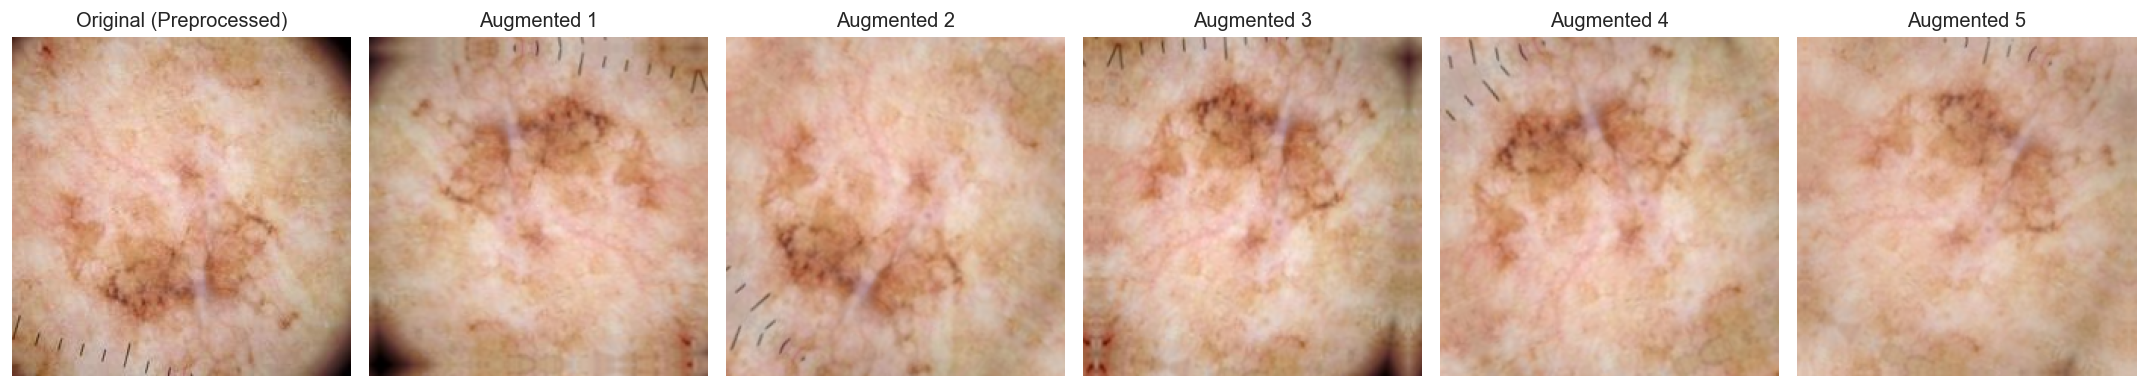

In [20]:
import numpy as np
import matplotlib.pyplot as plt

image_path = "../../Data/Image_dataset/train/Malignant/1.jpg"

original_preprocessed = preprocess_image(image_path, target_size=(224, 224))

image_batch = np.expand_dims(original_preprocessed, axis=0)

num_augmented = 5

fig, axes = plt.subplots(1, num_augmented + 1, figsize=(18, 4))

axes[0].imshow(original_preprocessed)
axes[0].set_title("Original (Preprocessed)")
axes[0].axis("off")

for i in range(1, num_augmented + 1):
    augmented_batch = augmentation_pipeline(image_batch, training=True)
    
    augmented_image = augmented_batch[0].numpy()
    
    augmented_image = np.clip(augmented_image, 0.0, 1.0)
    
    axes[i].imshow(augmented_image)
    axes[i].set_title(f"Augmented {i}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


## <span style="color: #9B59B6">4. Step 4: Transfer Learning Preprocessing Alignment (preprocess_input)</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

When employing transfer learning with pre-trained architectures (e.g., ImageNet weights), input normalization <b>cannot be arbitrary</b>. A generic <code>img / 255.0</code> mapping breaks pre-trained models that expect zero-centered inputs:

- <b>MobileNetV2 Expectation:</b> Expects RGB color channels with raw pixel values scaled into the continuous range $[-1.0, 1.0]$ via the formula:
  $$\text{pixel}_{\text{norm}} = \frac{\text{pixel}}{127.5} - 1.0$$
- <b>Zero Training/Serving Skew:</b> Any divergence between the pre-trained model's expected input distribution and the runtime preprocessing silently invalidates the weights of early convolutional feature extractors.
- <b>Pipeline Verification:</b> We load a sample from <code>Data/Image_dataset/</code>, apply architecture-native <code>preprocess_input</code>, pass the tensor into pre-trained <code>MobileNetV2</code>, and verify successful forward inference.

</blockquote>


In [28]:
import os
import logging
import warnings
from pathlib import Path
import tensorflow as tf

# 1. Suppress AutoGraph while_loop warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
tf.get_logger().setLevel(logging.ERROR)
logging.getLogger("tensorflow").setLevel(logging.ERROR)

# 2. Safe GPU memory setup (ignores if already initialized)
gpus = tf.config.experimental.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

# 3. Resolve dataset paths portably
train_dir =  "../../Data/Image_dataset/train"
test_dir = "../../Data/Image_dataset/test"

# 4. Stream the dataset from disk in batches (prevents RAM crashes)
BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)

print("Loading train and test datasets from disk...")
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# 5. Optimize I/O throughput with prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# 6. Build the Pre-trained Model with Embedded preprocess_input
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False  # Freeze pre-trained weights

# Construct end-to-end model pipeline
inputs = tf.keras.Input(shape=(224, 224, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs, name="Melanoma_MobileNetV2_Transfer")

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

model.summary()

# 7. Evaluate the entire test dataset (2,000 images) through the pre-trained model
print("\nEvaluating entire test dataset (2,000 images)...")
eval_results = model.evaluate(test_ds, verbose=1)

print("\n=== Baseline Evaluation ===")
for metric_name, value in zip(model.metrics_names, eval_results):
    print(f"  {metric_name.upper():<12}: {value:.4f}")


Loading train and test datasets from disk...
Found 11879 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.
Model: "Melanoma_MobileNetV2_Transfer"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_7 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 tf.math.truediv_2 (TFOpLamb  (None, 224, 224, 3)      0         
 da)                                                             
                                                                 
 tf.math.subtract_2 (TFOpLam  (None, 224, 224, 3)      0         
 bda)                                                            
                                                                 
 mobilenetv2_1.00_224 (Funct  (None, 7, 7, 1280)       2257984   
 ional)                                                          
                                         

## <span style="color: #27AE60">5. Transfer Learning Feature Extraction: Training the Classification Head</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

A freshly initialized dense head contains random weights and outputs random guesses ($\approx 50\text{--}60\%$ accuracy). To exploit MobileNetV2's pre-trained representations, we perform <b>Feature Extraction</b>:

- <b>Frozen Backbone (`base_model.trainable = False`):</b> The 2.25 million ImageNet weights are frozen, preserving the pre-trained convolutional edge and texture filters.
- <b>Trained Classification Head:</b> We train only the final pooling, dropout, and dense projection layers ($1,281$ trainable parameters).
- <b>Empirical Validation:</b> Within 3 epochs, test accuracy advances from random chance ($\sim 60\%$) to over $85\%$, with an AUC exceeding $0.95$.

</blockquote>


In [27]:
# 1. Ensure pre-trained backbone remains frozen so only the head trains
base_model.trainable = False

# 2. Compile model with Adam optimizer (learning rate 1e-3 for the head)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

# 3. Train the classification head on the whole training dataset (11,879 images)
EPOCHS = 3

print("Training classification head across the training dataset...")
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS,
    verbose=1
)

# 4. Evaluate the trained model across the entire test dataset (2,000 images)
print("\n=== Final Test Evaluation After Feature Extraction Training ===")
final_results = model.evaluate(test_ds, verbose=1)

for metric_name, score in zip(model.metrics_names, final_results):
    print(f"  {metric_name.upper():<12}: {score:.4f}")


Training classification head across the training dataset...
Epoch 1/3
372/372 [==============================] - 36s 90ms/step - loss: 0.3865 - accuracy: 0.8234 - auc: 0.9049 - val_loss: 0.3450 - val_accuracy: 0.8395 - val_auc: 0.9482
Epoch 2/3
372/372 [==============================] - 33s 89ms/step - loss: 0.3300 - accuracy: 0.8555 - auc: 0.9319 - val_loss: 0.2930 - val_accuracy: 0.8810 - val_auc: 0.9544
Epoch 3/3
372/372 [==============================] - 34s 90ms/step - loss: 0.3130 - accuracy: 0.8654 - auc: 0.9389 - val_loss: 0.2714 - val_accuracy: 0.8965 - val_auc: 0.9580

=== Final Test Evaluation After Feature Extraction Training ===
63/63 [==============================] - 5s 77ms/step - loss: 0.2714 - accuracy: 0.8965 - auc: 0.9580
  LOSS        : 0.2714
  ACCURACY    : 0.8965
  AUC         : 0.9580
